<a href="https://colab.research.google.com/github/Niranjan0345/CN-Assingment/blob/main/CBL_TASK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, glob, zipfile, random, time, hashlib, numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from google.colab import files

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print(torch.__version__, dev)

2.11.0+cu130 cuda


Saving Indian Coin Currency Dataset.zip to Indian Coin Currency Dataset.zip
data/Indian Coin Currency Dataset
['1 Rupee Coin', '10 Rupee Coin', '2 Rupee Coin', '5 Rupee Coin'] Counter({0: 666, 3: 512, 2: 447, 1: 183})


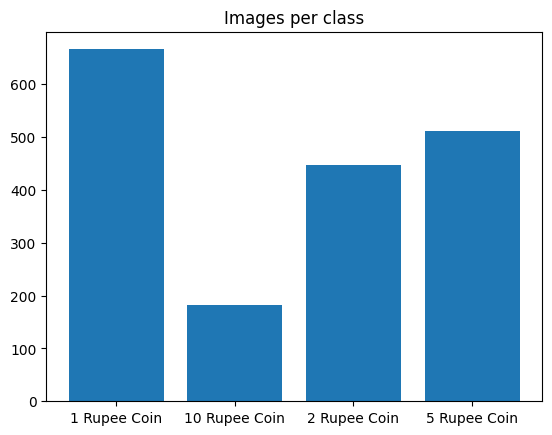

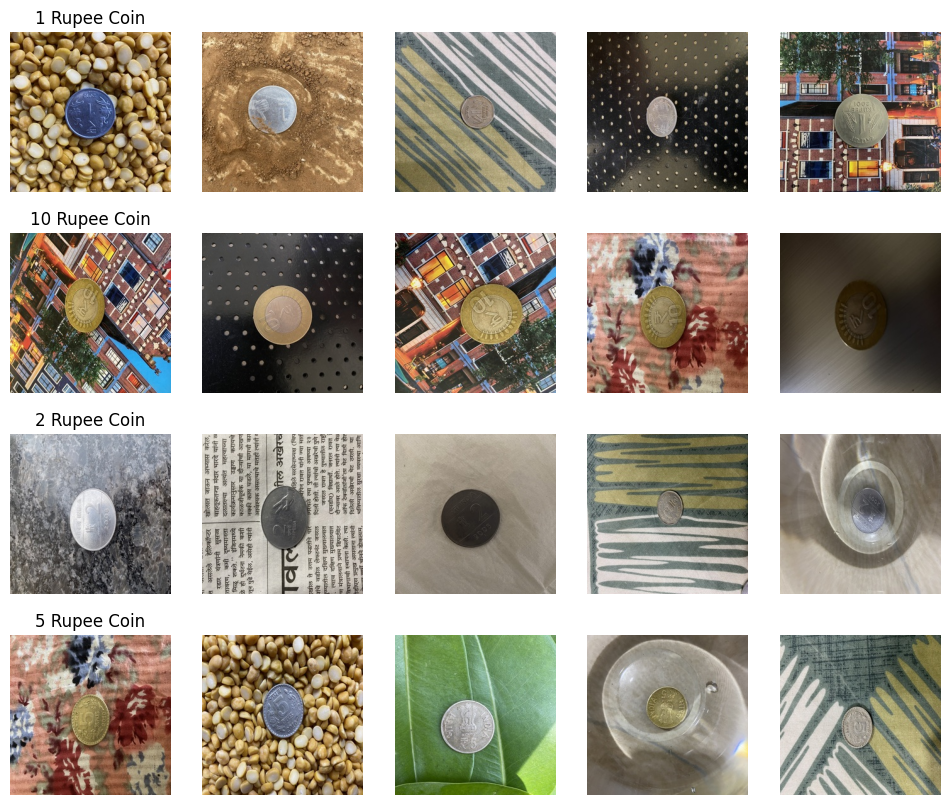

In [2]:
up = files.upload()
for f in up:
    if f.endswith('.zip'): zipfile.ZipFile(f).extractall('data')

def find_root(base):
    for d, subs, _ in os.walk(base):
        if len(subs) >= 2 and all(glob.glob(f'{d}/{s}/*.[jJpP][pPnN]*[gG]') for s in subs):
            return d
ROOT = find_root('data'); print(ROOT)

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_tr = transforms.Compose([transforms.Resize((256, 256)), transforms.RandomResizedCrop(224, scale=(0.7, 1)),
                            transforms.RandomRotation(30), transforms.ColorJitter(0.3, 0.3, 0.3),
                            transforms.ToTensor(), transforms.Normalize(mean, std)])
tf_ev = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(mean, std)])

ds_tr, ds_ev = datasets.ImageFolder(ROOT, tf_tr), datasets.ImageFolder(ROOT, tf_ev)
classes, NC, y = ds_ev.classes, len(ds_ev.classes), np.array(ds_ev.targets)
print(classes, Counter(y.tolist()))

plt.bar(classes, [Counter(y.tolist())[i] for i in range(NC)]); plt.title('Images per class'); plt.show()
fig, ax = plt.subplots(NC, 5, figsize=(12, 2.5*NC))
for c in range(NC):
    for j, i in enumerate(np.random.choice(np.where(y == c)[0], 5, replace=False)):
        ax[c, j].imshow(Image.open(ds_ev.samples[i][0])); ax[c, j].axis('off')
        if j == 0: ax[c, j].set_title(classes[c])
plt.show()

In [3]:
idx = np.arange(len(y))
tr_i, tmp_i = train_test_split(idx, test_size=0.3, stratify=y, random_state=SEED)
va_i, te_i = train_test_split(tmp_i, test_size=0.5, stratify=y[tmp_i], random_state=SEED)
np.savez('split.npz', tr=tr_i, va=va_i, te=te_i)
print(len(tr_i), len(va_i), len(te_i))

md5 = lambda p: hashlib.md5(open(p, 'rb').read()).hexdigest()
h = {i: md5(ds_ev.samples[i][0]) for i in idx}
print('exact duplicates train/test:', len({h[i] for i in tr_i} & {h[i] for i in te_i}))

BS = 32
tr_dl = DataLoader(Subset(ds_tr, tr_i), BS, shuffle=True, num_workers=2)
va_dl = DataLoader(Subset(ds_ev, va_i), BS, num_workers=2)
te_dl = DataLoader(Subset(ds_ev, te_i), BS, num_workers=2)

cw = torch.tensor(len(tr_i) / (NC * np.bincount(y[tr_i])), dtype=torch.float).to(dev)
crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)

1265 271 272
exact duplicates train/test: 0


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 115MB/s] 


mobilenet_v2 1 tl=1.038 ta=0.562 vl=0.725 va=0.808
mobilenet_v2 2 tl=0.671 ta=0.840 vl=0.651 va=0.863
mobilenet_v2 3 tl=0.578 ta=0.905 vl=0.575 va=0.930
mobilenet_v2 4 tl=0.537 ta=0.931 vl=0.554 va=0.926
mobilenet_v2 5 tl=0.513 ta=0.949 vl=0.507 va=0.956
mobilenet_v2 6 tl=0.503 ta=0.952 vl=0.557 va=0.937
mobilenet_v2 7 tl=0.488 ta=0.965 vl=0.505 va=0.952
mobilenet_v2 8 tl=0.478 ta=0.974 vl=0.505 va=0.948
mobilenet_v2 9 tl=0.475 ta=0.967 vl=0.572 va=0.919
mobilenet_v2 10 tl=0.483 ta=0.970 vl=0.532 va=0.919
mobilenet_v2 11 tl=0.468 ta=0.975 vl=0.495 va=0.948
mobilenet_v2 12 tl=0.451 ta=0.987 vl=0.489 va=0.956
mobilenet_v2 13 tl=0.447 ta=0.987 vl=0.483 va=0.963
mobilenet_v2 14 tl=0.447 ta=0.988 vl=0.489 va=0.959
mobilenet_v2 15 tl=0.445 ta=0.987 vl=0.482 va=0.956
mobilenet_v2 16 tl=0.444 ta=0.986 vl=0.484 va=0.956
mobilenet_v2 17 tl=0.441 ta=0.989 vl=0.479 va=0.963
mobilenet_v2 18 tl=0.443 ta=0.991 vl=0.484 va=0.967
mobilenet_v2 19 tl=0.439 ta=0.995 vl=0.492 va=0.970
mobilenet_v2 20 tl=0.

100%|██████████| 44.7M/44.7M [00:00<00:00, 143MB/s]


resnet18 1 tl=0.887 ta=0.707 vl=0.699 va=0.845
resnet18 2 tl=0.607 ta=0.898 vl=0.555 va=0.926
resnet18 3 tl=0.549 ta=0.933 vl=0.596 va=0.904
resnet18 4 tl=0.500 ta=0.964 vl=0.542 va=0.948
resnet18 5 tl=0.507 ta=0.958 vl=0.490 va=0.963
resnet18 6 tl=0.495 ta=0.965 vl=0.588 va=0.878
resnet18 7 tl=0.503 ta=0.957 vl=0.551 va=0.930
resnet18 8 tl=0.490 ta=0.967 vl=0.705 va=0.897
resnet18 9 tl=0.480 ta=0.972 vl=0.480 va=0.963
resnet18 10 tl=0.460 ta=0.981 vl=0.471 va=0.978
resnet18 11 tl=0.444 ta=0.991 vl=0.466 va=0.982
resnet18 12 tl=0.443 ta=0.994 vl=0.469 va=0.982
resnet18 13 tl=0.448 ta=0.987 vl=0.474 va=0.974
resnet18 14 tl=0.445 ta=0.991 vl=0.466 va=0.978
resnet18 15 tl=0.447 ta=0.991 vl=0.464 va=0.978
resnet18 16 tl=0.438 ta=0.994 vl=0.465 va=0.978
resnet18 17 tl=0.441 ta=0.994 vl=0.465 va=0.978
resnet18 18 tl=0.448 ta=0.987 vl=0.466 va=0.978
resnet18 19 tl=0.439 ta=0.994 vl=0.463 va=0.978
resnet18 20 tl=0.440 ta=0.995 vl=0.466 va=0.978
mobilenet_v2 best val acc 0.974169741697417 time 

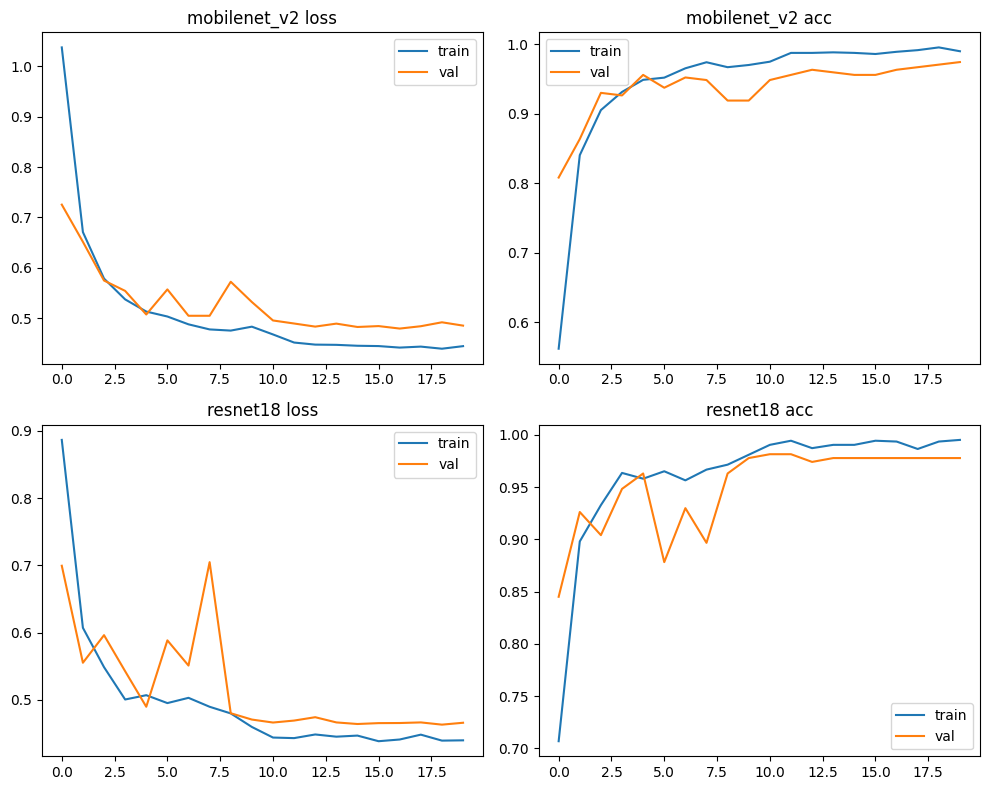

In [4]:
def build(name):
    if name == 'mobilenet_v2':
        m = models.mobilenet_v2(weights='DEFAULT'); m.classifier[1] = nn.Linear(m.last_channel, NC)
    else:
        m = models.resnet18(weights='DEFAULT'); m.fc = nn.Linear(m.fc.in_features, NC)
    return m.to(dev)

def epoch(m, dl, train, opt=None):
    m.train(train); L = A = N = 0
    with torch.set_grad_enabled(train):
        for x, t in dl:
            x, t = x.to(dev), t.to(dev); o = m(x); l = crit(o, t)
            if train: opt.zero_grad(); l.backward(); opt.step()
            L += l.item()*len(t); A += (o.argmax(1) == t).sum().item(); N += len(t)
    return L/N, A/N

def run(name, epochs=20, patience=5):
    torch.manual_seed(SEED)
    m = build(name); opt = torch.optim.AdamW(m.parameters(), 3e-4, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=2)
    H = {k: [] for k in ['tl', 'ta', 'vl', 'va']}; best, state, bad, t0 = 1e9, None, 0, time.time()
    for e in range(epochs):
        tl, ta = epoch(m, tr_dl, True, opt); vl, va = epoch(m, va_dl, False)
        for k, v in zip(H, [tl, ta, vl, va]): H[k].append(v)
        sch.step(vl); print(f'{name} {e+1} tl={tl:.3f} ta={ta:.3f} vl={vl:.3f} va={va:.3f}')
        if vl < best: best, bad = vl, 0; state = {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(state)
    return m, H, time.time() - t0

R = {n: run(n) for n in ['mobilenet_v2', 'resnet18']}
for n, (m, H, t) in R.items(): print(n, 'best val acc', max(H['va']), 'time', round(t, 1))

fig, ax = plt.subplots(len(R), 2, figsize=(10, 4*len(R)))
for r, (n, (m, H, t)) in enumerate(R.items()):
    ax[r, 0].plot(H['tl'], label='train'); ax[r, 0].plot(H['vl'], label='val'); ax[r, 0].set_title(n + ' loss'); ax[r, 0].legend()
    ax[r, 1].plot(H['ta'], label='train'); ax[r, 1].plot(H['va'], label='val'); ax[r, 1].set_title(n + ' acc'); ax[r, 1].legend()
plt.tight_layout(); plt.show()

selected: resnet18
Test acc: 0.99 | Macro F1: 0.99
               precision    recall  f1-score   support

 1 Rupee Coin       0.99      0.97      0.98       100
10 Rupee Coin       1.00      1.00      1.00        28
 2 Rupee Coin       0.97      0.99      0.98        67
 5 Rupee Coin       0.99      1.00      0.99        77

     accuracy                           0.99       272
    macro avg       0.99      0.99      0.99       272
 weighted avg       0.99      0.99      0.99       272



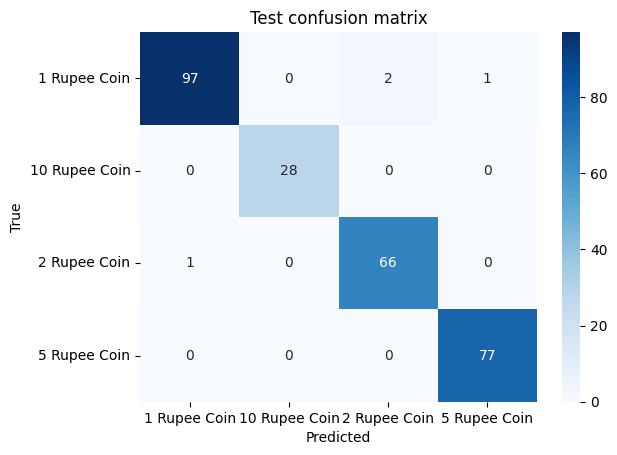

Params: 11.18M | Size: 44.7 MB | Inference: 5.6 ms/img | Train time: 152s


In [5]:
best_name = max(R, key=lambda n: max(R[n][1]['va']))
model, H, ttime = R[best_name]; print('selected:', best_name)

model.eval(); P, T = [], []
with torch.no_grad():
    for x, t in te_dl: P += model(x.to(dev)).argmax(1).cpu().tolist(); T += t.tolist()
P, T = np.array(P), np.array(T)

print(f'Test acc: {accuracy_score(T, P):.2f} | Macro F1: {f1_score(T, P, average="macro"):.2f}')
print(classification_report(T, P, target_names=classes, digits=2))
cm = confusion_matrix(T, P)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Test confusion matrix'); plt.show()

x = torch.randn(1, 3, 224, 224).to(dev)
with torch.no_grad():
    for _ in range(10): model(x)
    t0 = time.time()
    for _ in range(100): model(x)
print(f'Params: {sum(p.numel() for p in model.parameters())/1e6:.2f}M | '
      f'Size: {sum(p.numel() for p in model.parameters())*4/1e6:.1f} MB | '
      f'Inference: {(time.time()-t0)*10:.1f} ms/img | Train time: {ttime:.0f}s')

4 errors


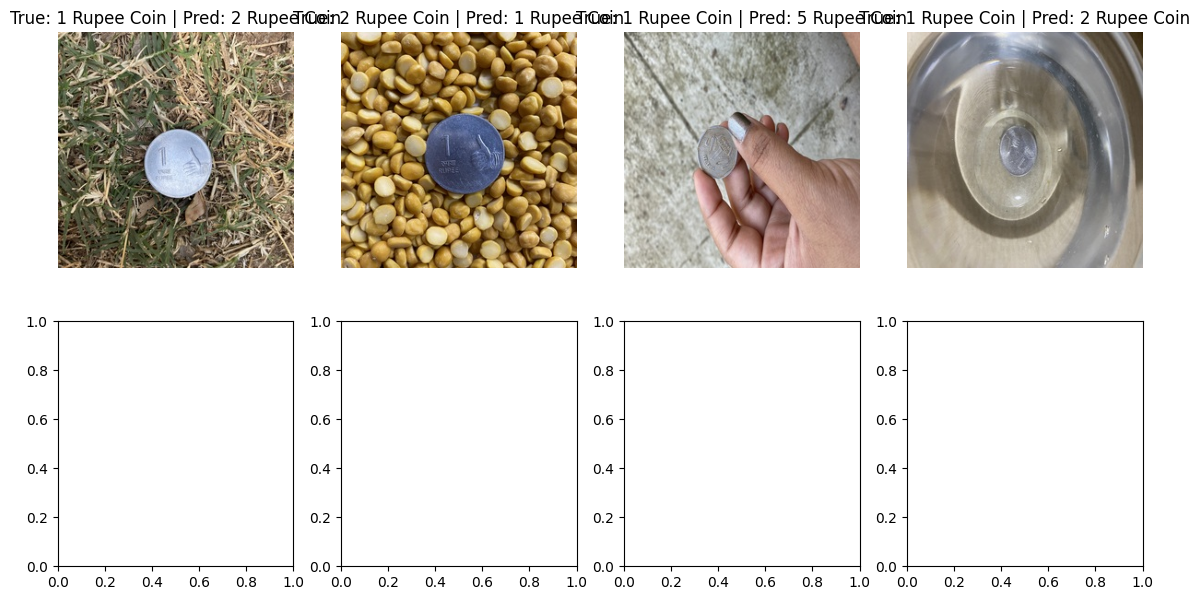

In [6]:
wrong = np.where(P != T)[0]; print(len(wrong), 'errors')
n = min(8, len(wrong)); fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for a, w in zip(ax.ravel(), wrong[:n]):
    a.imshow(Image.open(ds_ev.samples[te_i[w]][0])); a.axis('off')
    a.set_title(f'True: {classes[T[w]]} | Pred: {classes[P[w]]}')
plt.show()

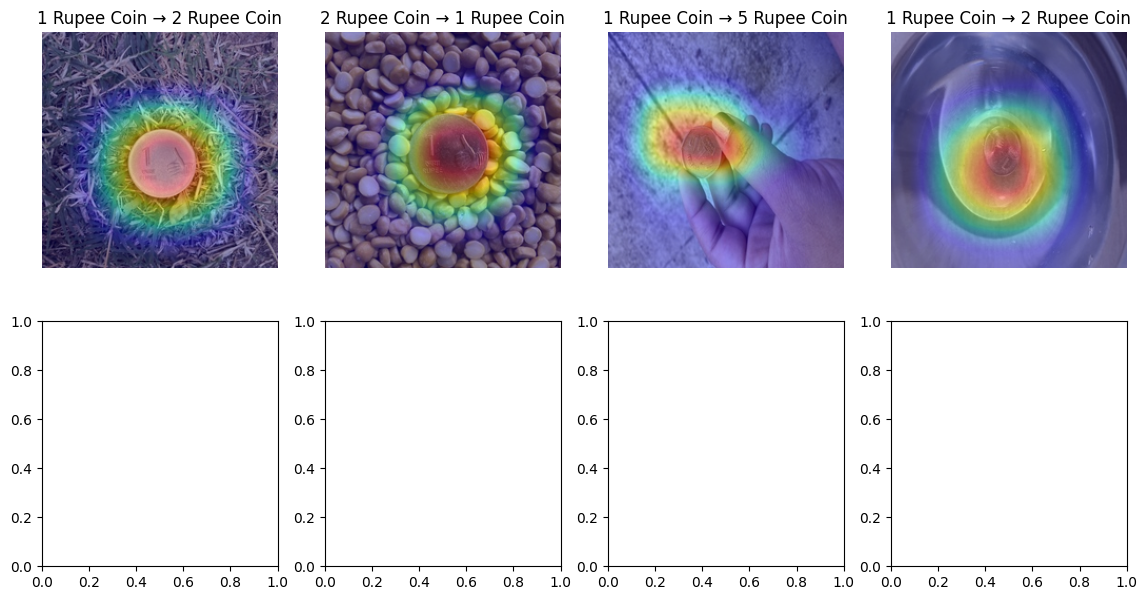

In [7]:
from torchvision.transforms.functional import to_pil_image
def gradcam(model, x, layer):
    f, g = {}, {}
    h1 = layer.register_forward_hook(lambda m, i, o: f.update(a=o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: g.update(a=go[0]))
    o = model(x); o[0, o.argmax()].backward()
    h1.remove(); h2.remove()
    w = g['a'].mean((2, 3), keepdim=True); cam = torch.relu((w*f['a']).sum(1))[0].detach().cpu()
    return (cam / cam.max()).numpy()

layer = model.features[-1] if best_name == 'mobilenet_v2' else model.layer4[-1]
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for a, w in zip(ax.ravel(), wrong[:n]):
    xi = ds_ev[te_i[w]][0].unsqueeze(0).to(dev)
    cam = np.array(Image.fromarray((gradcam(model, xi, layer)*255).astype('uint8')).resize((224, 224)))
    a.imshow(Image.open(ds_ev.samples[te_i[w]][0]).resize((224, 224))); a.imshow(cam, cmap='jet', alpha=0.4); a.axis('off')
    a.set_title(f'{classes[T[w]]} → {classes[P[w]]}')
plt.show()